In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler  # for scaling time features

In [10]:
# Base directory for AntM2C 10M dataset
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"

# Main preprocessed folder
preprocessed_dir = f"{base_dir}/AntM2C_preprocessed"

# Time-related CSV from split_features
time_features_csv = f"{preprocessed_dir}/split_features/df_time.csv"

# Combined preprocessed dataframe
df_processed_pkl = f"{preprocessed_dir}/df_processed.pkl"

# Interactions CSV (if needed later)
# interactions_csv = f"{preprocessed_dir}/interactions_clean.csv"   # if exists in your workflow

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [12]:
df_time = pd.read_csv(time_features_csv)

print("Loaded df_time.csv with shape:", df_time.shape)
df_time.head()

Loaded df_time.csv with shape: (3730329, 6)


,log_time,hour,dayofweek,is_weekend,hour_sin,hour_cos
0,2023-07-14 00:21:44,0,4,False,0.000000e+00,1.000000
1,2023-07-18 12:45:30,12,1,False,1.224647e-16,-1.000000
2,2023-08-01 09:28:15,9,1,False,7.071068e-01,-0.707107
3,2023-08-03 23:19:06,23,3,False,-2.588190e-01,0.965926
4,2023-08-01 20:24:21,20,1,False,-8.660254e-01,0.500000


The df_time.csv file contains the pre-engineered temporal features for each interaction.
These include:
*   log_time: Original timestamp in datetime format
*   hour: Hour of day (0–23)
*   dayofweek: Day of week (0–6)
*   is_weekend: Boolean indicating weekend/weekday
*   hour_sin, hour_cos: Cyclic encodings of hour-of-day

This preprocessing was already performed during dataset preparation, so this notebook focuses on validating the data and preparing it for Time2Vec integration.

#### Convert log_time to datetime

In [13]:
df_time["datetime"] = pd.to_datetime(df_time["log_time"], errors='coerce')
print(df_time["datetime"].describe())

count                          3730329
mean     2023-07-25 21:51:35.364042496
min                2023-07-10 00:00:02
25%                2023-07-18 08:19:42
50%                2023-07-25 22:23:26
75%                2023-08-02 16:09:55
max                2023-08-09 23:59:59
Name: datetime, dtype: object


#### Check for missing timestamps

In [14]:
missing_ts = df_time["datetime"].isna().sum()
print("Missing timestamps:", missing_ts)

Missing timestamps: 0


#### Plot hourly distribution

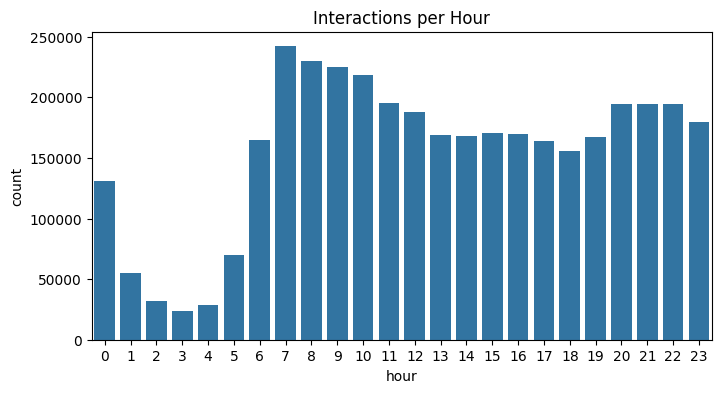

In [15]:
plt.figure(figsize=(8,4))
sns.countplot(x=df_time["hour"])
plt.title("Interactions per Hour")
plt.show()

#### Plot weekday distribution

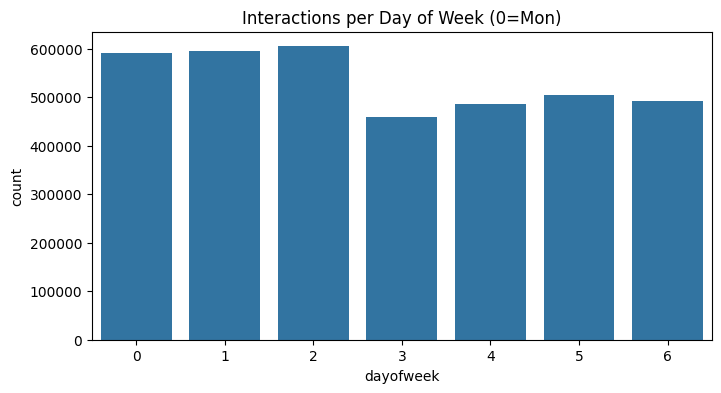

In [16]:
plt.figure(figsize=(8,4))
sns.countplot(x=df_time["dayofweek"])
plt.title("Interactions per Day of Week (0=Mon)")
plt.show()

#### Check cyclic encoding range

In [17]:
print("hour_sin range:", df_time["hour_sin"].min(), df_time["hour_sin"].max())
print("hour_cos range:", df_time["hour_cos"].min(), df_time["hour_cos"].max())

hour_sin range: -1.0 1.0
hour_cos range: -1.0 1.0


### Engineer Base Time Features

The AntM2C preprocessed time file already includes several engineered temporal features such as:


*   Hour of day
*   Day of week
*   Weekend indicator
*   Cyclic encodings (hour_sin, hour_cos)

However, the Time2Vec module requires at least one continuous time signal, typically:
*   A normalized Unix timestamp, or
*   A continuous “time since start/end” measure

Therefore, this step adds a continuous normalized timestamp (unix_time_norm) that captures global temporal drift across the dataset.

We then:
1.   Convert log_time into a Unix timestamp
2.   Normalize it using StandardScaler
3.   Convert boolean flags to numeric (e.g., is_weekend -> 0/1)
4.   Build the final set of features to feed into Time2Vec

These encoded time features will be used as inputs to the Time2Vec layer in the full ColdFusionX architecture.

In [18]:
# Convert log_time -> Unix time (continuous)

# (Just to make sure date time is created)
df_time["datetime"] = pd.to_datetime(df_time["log_time"], errors='coerce')

# Convert to Unix timestamp in seconds (int)
df_time["unix_time"] = df_time["datetime"].astype('int64') // 1_000_000_000

print(df_time[["log_time", "datetime", "unix_time"]].head())

              log_time            datetime   unix_time
0  2023-07-14 00:21:44 2023-07-14 00:21:44  1689294104
1  2023-07-18 12:45:30 2023-07-18 12:45:30  1689684330
2  2023-08-01 09:28:15 2023-08-01 09:28:15  1690882095
3  2023-08-03 23:19:06 2023-08-03 23:19:06  1691104746
4  2023-08-01 20:24:21 2023-08-01 20:24:21  1690921461


In [19]:
# Normalize Unix Time (Essential for Time2Vec)
scaler = StandardScaler()

df_time["unix_time_norm"] = scaler.fit_transform(
    df_time[["unix_time"]]
)

print(df_time["unix_time_norm"].describe())

count    3.730329e+06
mean     6.471484e-14
std      1.000000e+00
min     -1.784405e+00
25%     -8.482854e-01
50%      2.480079e-03
75%      8.705938e-01
max      1.692257e+00
Name: unix_time_norm, dtype: float64


 Saving scaler stats for reproducibility

In [20]:
scaler_stats = {
    "mean": float(scaler.mean_),
    "scale": float(scaler.scale_)
}

with open(f"{preprocessed_dir}/split_features/scaler_stats_time.json", "w") as f:
    json.dump(scaler_stats, f)

scaler_stats

{'mean': 1690321895.3640416, 'scale': 770393.2955774534}

### Convert boolean features (e.g., is_weekend) to numeric

In [21]:
if df_time["is_weekend"].dtype == "object":
    df_time["is_weekend"] = df_time["is_weekend"].map({"true": 1, "false": 0})

df_time["is_weekend"] = df_time["is_weekend"].astype(int)

Selecting the final Time Features for Time2Vec

In [22]:
time_feature_cols = [
    "unix_time_norm",
    "hour_sin",
    "hour_cos",
    "dayofweek",
    "is_weekend"
]

df_time_features = df_time[time_feature_cols]

print("Selected time feature columns:", time_feature_cols)
df_time_features.head()

Selected time feature columns: ['unix_time_norm', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend']


,unix_time_norm,hour_sin,hour_cos,dayofweek,is_weekend
0,-1.334113,0.000000e+00,1.000000,4,0
1,-0.827584,1.224647e-16,-1.000000,1,0
2,0.727161,7.071068e-01,-0.707107,1,0
3,1.016170,-2.588190e-01,0.965926,3,0
4,0.778259,-8.660254e-01,0.500000,1,0


Convert to PyTorch Tensor

In [23]:
time_features_tensor = torch.tensor(
    df_time_features.values, dtype=torch.float32
)

print("Tensor shape:", time_features_tensor.shape)

Tensor shape: torch.Size([3730329, 5])


Save the Time Featueres

In [24]:
torch.save(
    time_features_tensor,
    f"{preprocessed_dir}/time_features_raw.pt"
)

with open(f"{preprocessed_dir}/time_feature_columns.json", "w") as f:
    json.dump(time_feature_cols, f)

print("Saved time features and column metadata.")

Saved time features and column metadata.


##Define the Time2Vec Encoder (PyTorch Module)

Time2Vec is a learnable time representation proposed by Kazemi & Goel (2019).
Unlike fixed sinusoidal encodings, Time2Vec learns both:
*   A linear component to capture global temporal trends
*   Several periodic components (sine terms) to model recurring patterns

For a time input vector t (e.g. [unix_time_norm, hour_sin, hour_cos, dayofweek, is_weekend]), Time2Vec learns:
*   One linear projection: L(t) = w₀ᵀ t + b₀
*   Several periodic projections: Pᵢ(t) = sin(wᵢᵀ t + bᵢ) for i = 1…k

The final Time2Vec embedding is the concatenation:

Time2Vec(t) = 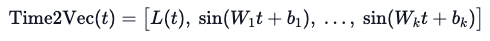

In this notebook, we implement a general Time2Vec PyTorch layer:
*   Input shape: (batch_size, in_features) -> here: (N, 5)
*   Output shape: (batch_size, out_features) where out_features = 1 + k
*   The layer is fully differentiable and will be trained jointly with the CTR model.

This notebook will:
1.   Define the Time2Vec module
2.   Instantiate it with the current time feature dimension (5)
3.   Test it on a random batch to verify shape and value ranges

In [34]:
class Time2Vec(nn.Module):
    """
    Time2Vec layer as described by Kazemi & Goel (2019).

    Given an input of shape (batch_size, in_features),
    outputs a time embedding of shape (batch_size, out_features),
    where out_features = linear_dim + periodic_dim.

    We use:
      - 1 linear component
      - (k) periodic components with sine activations
    """
    def __init__(self, in_features: int, k: int):
        """
        Args:
            in_features: number of input time features (e.g. 5)
            k: number of periodic components (embedding_dim = 1 + k)
        """
        super(Time2Vec, self).__init__()

        # Linear part: scalar per time vector
        self.linear = nn.Linear(in_features, 1)

        # Periodic part: k sine components
        self.periodic = nn.Linear(in_features, k)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: tensor of shape (batch_size, in_features)
        Returns:
            Tensor of shape (batch_size, 1 + k)
        """
        # Linear component
        v_linear = self.linear(x)                 # (B, 1)

        # Periodic component
        v_periodic = torch.sin(self.periodic(x))  # (B, k)

        # Concatenate along last dimension
        return torch.cat([v_linear, v_periodic], dim=-1)

We already know,

In [35]:
time_features_tensor.shape  # torch.Size([3730329, 5])

torch.Size([3730329, 5])

Therefore,
*   in_features = 5
*   Choose e.g. k = 7 → total time embedding dim = 8

In [36]:
in_features = time_features_tensor.shape[1]  # 5
k = 7                                        # periodic components
time2vec_dim = 1 + k                         # total output dimensions

time2vec_layer = Time2Vec(in_features=in_features, k=k).to(device)
print(time2vec_layer)

Time2Vec(
  (linear): Linear(in_features=5, out_features=1, bias=True)
  (periodic): Linear(in_features=5, out_features=7, bias=True)
)


Testing on a Small Batch

In [37]:
# Take a small random subset for testing
batch_idx = torch.randint(0, time_features_tensor.shape[0], (1024,))
time_batch = time_features_tensor[batch_idx].to(device)  # (1024, 5)

with torch.no_grad():
    t2v_out = time2vec_layer(time_batch)

print("Input shape:", time_batch.shape)         # (1024, 5)
print("Output shape:", t2v_out.shape)           # (1024, 8)
print("First row (Time2Vec embedding):")
print(t2v_out[0])

Input shape: torch.Size([1024, 5])
Output shape: torch.Size([1024, 8])
First row (Time2Vec embedding):
tensor([-0.2118, -0.2394,  0.7116, -0.2542,  0.4126, -0.3638,  0.4481,  0.5988])
